# 02 — Veri Temizliği ve Anomali Analizi (Öğrenci 2)

**Görev:** Eksik/hatalı kayıtları temizlemek; anormal mesafe, ücret ve süre değerlerini analiz etmek.

Bu notebook ölçüm yapmaz; hesaplar 19M kayıt üzerinde Spark ile tekrar üretilebilir scriptlerle alınmış ve `reports/results/` altına yazılmıştır. Burada sonuçlar okunur, görselleştirilir ve **yorumlanır**.

| Adım | Script | Çıktı |
|---|---|---|
| T2.1 Profil | `python -m src.profile_data` | `profile_raw.csv`, `logic_checks_raw.csv` |
| T2.2 Temizlik + T2.4 teslim | `python -m src.clean` | `data/clean/`, `cleaning_impact.csv`, `cleaning_before_after.csv` |
| T2.3 Anomali | `python -m src.anomaly` | `anomaly_*.csv`, `data/samples/` |
| T2.5 Grafikler | bu notebook (`src/plots_clean.py`) | `reports/figures/06–10_*.png` |

Kural tanımları ve gerekçeleri: [`docs/cleaning_rules.md`](../docs/cleaning_rules.md) · Temiz veri şeması: [`docs/data_dictionary.md` §8](../docs/data_dictionary.md).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import config, plots_clean as pc

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 200)
R, S, FIG = config.RESULTS_DIR, config.DATA_DIR / "samples", config.FIGURES_DIR
read = lambda name: pd.read_csv(R / f"{name}.csv")

## 1. Profil: veride ne var?

19M kaydın tamamında her sayısal kolonun dağılımı ve 14 mantıksal kontrol hesaplandı. Kontroller `src/quality.py` içinde **tek yerde** tanımlı; profil, temizlik ve anomali analizi aynı tanımları kullanır (tutarsızlık riski yok).

In [2]:
profile = read("profile_raw")
profile[["column", "nulls", "mean", "min", "p1", "p50", "p99", "p99.9", "max"]]

,column,nulls,mean,min,p1,p50,p99,p99.9,max
0,passenger_count,4812280,1.24,0.00,1.00,1.00,4.00,6.00,9.00
1,trip_distance,0,5.74,0.00,0.00,1.83,19.50,29.91,"328,522.20"
2,fare_amount,0,21.27,"-2,555.20",3.00,15.60,80.96,143.00,"5,525.99"
3,extra,0,1.09,-7.50,0.00,0.00,7.00,10.75,20.71
4,mta_tax,0,0.49,-0.50,0.00,0.50,0.50,0.50,10.50
5,tip_amount,0,2.82,-222.00,0.00,2.00,17.44,29.44,766.00
6,tolls_amount,0,0.52,-111.79,0.00,0.00,7.46,21.97,"1,400.00"
7,improvement_surcharge,0,0.95,-1.00,0.00,1.00,1.00,1.00,2.50
8,total_amount,0,29.98,"-2,560.20",7.75,23.58,105.27,177.04,"5,530.74"
9,congestion_surcharge,4812280,2.18,-2.50,0.00,2.50,2.50,2.50,2.50


**Okuma:** Ortalama ile medyan arasındaki uçurum veri kalitesinin ilk işaretidir. `trip_distance` ortalaması 5,7 mil ama medyanı 1,8 mil; maksimum **328.522 mil** (Dünya'nın çevresi ~24.900 mil). `avg_speed_mph` maksimumu 4,8 milyon mph. Ama p99,9 değerleri makul (29,9 mil, 125 dk, 46,7 mph) → sorun verinin gövdesinde değil, **ince bir kuyrukta**.

**Eksik değerler rastgele değil:** null içeren 5 kolonun hepsinde null sayısı birebir aynı (4.812.280). Bunlar tam olarak `payment_type = 0` (Flex Fare, uygulamadan ön fiyatlı yolculuk) kayıtları; taksimetre bu alanları doldurmuyor. Bu yüzden **null tek başına silme nedeni sayılmadı** ve hiçbir kolonda doldurma (imputation) yapılmadı — ortalama ile doldurmak Flex Fare yolculuklarını yanlışlıkla "standart" gösterirdi.

In [3]:
read("logic_checks_raw")

,check,rows,pct,flex_fare_rows,non_flex_rows
0,passenger_count_zero,64863,0.34,0.00,"64,863.00"
1,passenger_count_over_max,22,0.00,0.00,22.00
2,distance_zero_or_negative,576744,3.04,"407,165.00","169,579.00"
3,distance_over_max,767,0.00,516.00,251.00
4,fare_zero_or_negative,128776,0.68,"4,900.00","123,876.00"
5,total_zero_or_negative,121030,0.64,549.00,"120,481.00"
6,dropoff_before_pickup,5,0.00,3.00,2.00
7,duration_under_min,429347,2.26,"13,076.00","416,271.00"
8,duration_over_max,7145,0.04,181.00,"6,964.00"
9,speed_over_max,4928,0.03,"2,074.00","2,854.00"


## 2. Temizlik kuralları ve etkisi

10 kural (R1–R10) uygulandı; bir kurala takılan kayıt silinir. Her kural için üç sayı raporlanır, çünkü **kurallar örtüşür** ve tek sayı yanıltır:
- **Tek başına:** kuralın yakaladığı tüm kayıtlar,
- **Sıralı:** R1→R10 sırasıyla uygulanınca bu kuralın sildiği,
- **Yalnız bu kural:** başka hiçbir kuralın yakalamadığı (kural kaldırılsa veride kalacak olan).

R9 (tam kopya kayıt) **window** fonksiyonuyla bulunur: `row_number() over (partition by 20 ham kolon)` → her kopya grubunda ilki tutulur.

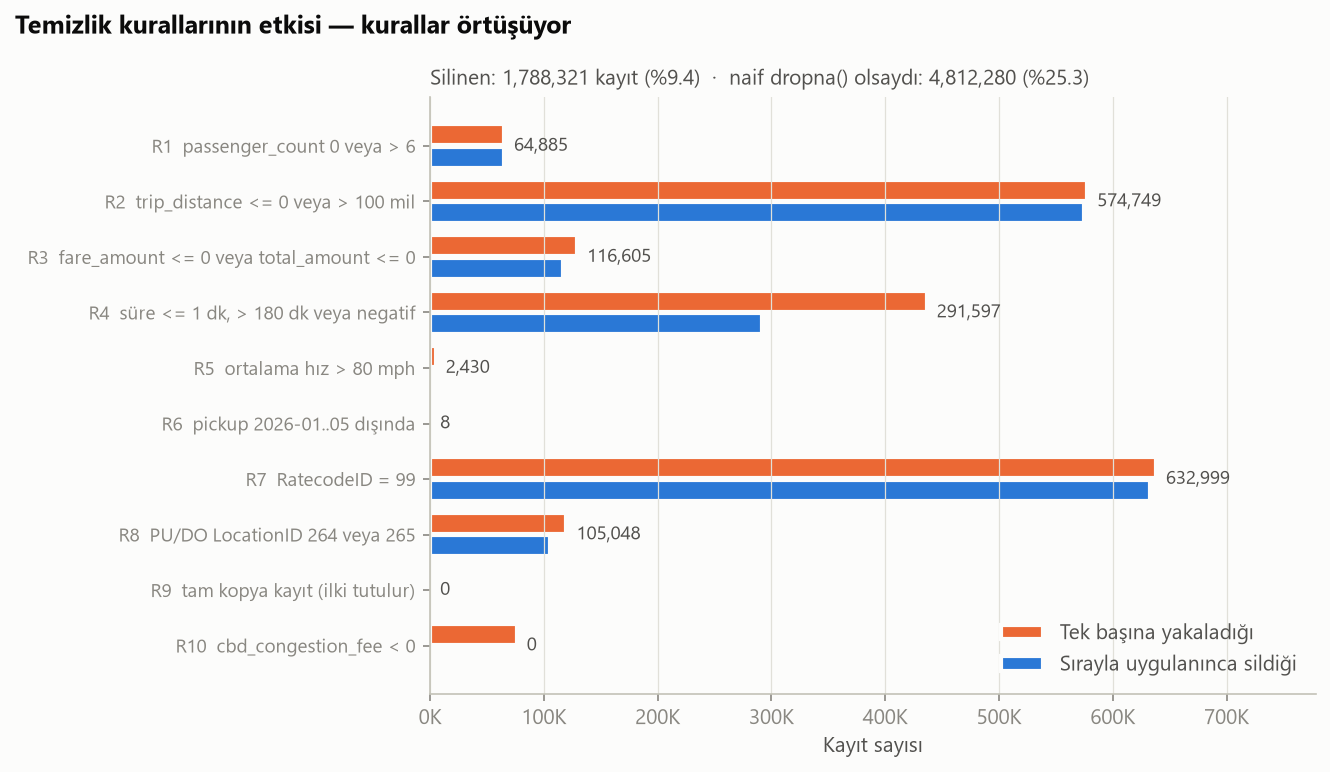

,rule,description,isolated,sequential,unique,sequential_pct
0,R1,passenger_count 0 veya > 6,"64,885.00",64885,"60,293.00",0.34
1,R2,trip_distance <= 0 veya > 100 mil,"577,511.00",574749,"435,051.00",3.02
2,R3,fare_amount <= 0 veya total_amount <= 0,"129,194.00",116605,"39,603.00",0.61
3,R4,"süre <= 1 dk, > 180 dk veya negatif","436,497.00",291597,"285,399.00",1.53
4,R5,ortalama hız > 80 mph,"4,928.00",2430,"1,709.00",0.01
5,R6,pickup 2026-01..05 dışında,15.00,8,8.00,0.00
6,R7,RatecodeID = 99,"637,889.00",632999,"632,500.00",3.33
7,R8,PU/DO LocationID 264 veya 265,"119,887.00",105048,"105,048.00",0.55
8,R9,tam kopya kayıt (ilki tutulur),0.00,0,0.00,0.00
9,R10,cbd_congestion_fee < 0,"76,131.00",0,0.00,0.00


In [4]:
display(Image(pc.plot_rule_impact(read("cleaning_impact"), FIG)))
read("cleaning_impact")[["rule", "description", "isolated", "sequential", "unique", "sequential_pct"]]

**Neden böyle?**
- **R4'te tek başına (436K) ile sıralı (292K) arasındaki fark:** süresi ≤ 1 dk olan kayıtların büyük kısmının mesafesi de sıfır → onları R2 daha önce siliyor. Aynı hatalı kayıt (iptal edilmiş yolculuk) birden çok belirti gösterir.
- **R10 sıralıda sıfır:** negatif CBD ücretli 76.131 kaydın tamamının toplam tutarı da negatif → R3 hepsini zaten siliyor. Bu kayıtlar ayrı bir hata değil, iade kayıtlarının bir belirtisi.
- **R9 sıfır:** 19M kayıtta tam kopya yok. Kural, gelecek veriler için tutuldu.
- **Naif temizlik:** `dropna()` 4,8M kayıt (%25,3) silerdi — tüm Flex Fare yolculuklarını. Kural bazlı yaklaşım bunun ~üçte biri kadar siler ve sildiği her kaydın gerekçesi vardır.

**Sonuç: 18.999.282 → 17.210.961 kayıt (%90,6 korundu).**

## 3. Temizlik öncesi / sonrası

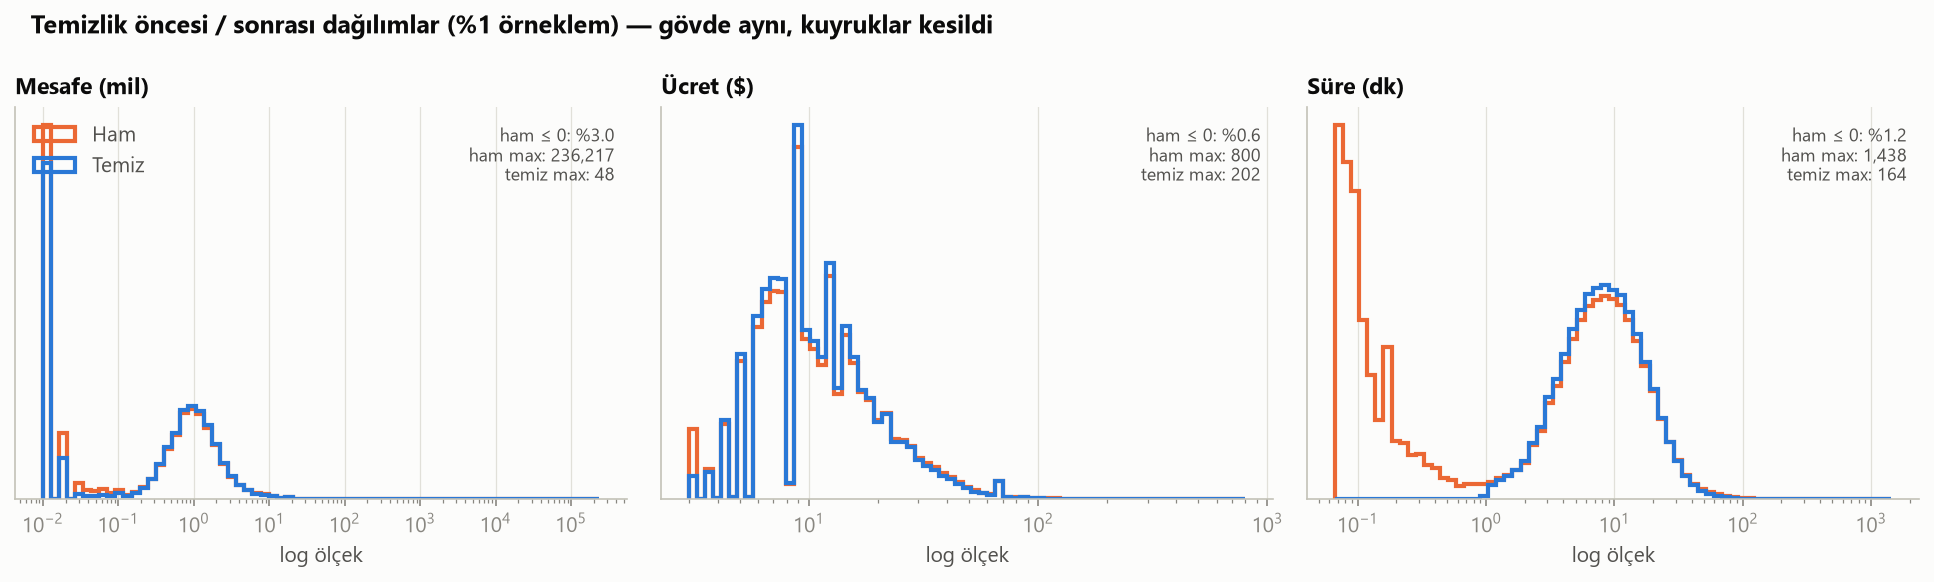

dataset,raw,clean
rows,"18,999,282.00","17,210,961.00"
trip_distance_mean,5.74,3.25
trip_distance_median,1.83,1.84
trip_distance_max,"328,522.20",94.76
fare_amount_mean,21.27,20.51
fare_amount_median,15.60,15.19
fare_amount_max,"5,525.99","1,061.72"
total_amount_mean,29.98,29.57
total_amount_median,23.58,23.18
total_amount_max,"5,530.74","1,065.72"


In [5]:
raw_s = pd.read_parquet(S / "raw_sample.parquet")
clean_s = pd.read_parquet(S / "clean_context_sample.parquet")
display(Image(pc.plot_before_after(raw_s, clean_s, FIG)))
read("cleaning_before_after").set_index("dataset").T

**Neden ortalamalar değişti ama medyanlar değişmedi?**
- Mesafe ortalaması **5,74 → 3,25 mil (−%43)**, medyanı **1,83 → 1,84**. Ortalama her değeri eşit ağırlıkla toplar; 328.522 millik tek bir kayıt, ortalamayı binlerce normal yolculuk kadar etkiler. Medyan ise yalnızca sıralamaya bakar, uç değerlerden etkilenmez.
- Grafikte dağılımların **gövdesi üst üste biniyor**: temizlik tipik yolculuğu değiştirmedi, yalnızca kuyrukları kesti (sıfır/negatif değerler ve imkânsız uç değerler).
- Süre panelinde ham verideki 0,1 dk civarındaki tepe tamamen kayboldu: bunlar iptal edilen yolculuklar ve Helix'in süre-sıfır kayıtları (bkz. §6).

**Sonraki analizler için ders:** temizlenmemiş veride ortalamaya dayanan her sonuç ("ortalama yolculuk 5,7 mil") yanlıştır. Öğrenci 3'ün aggregation'ları temiz veriyle yapılmalı.

## 4. Kural bazlı mı, istatistiksel mi?

Aynı ham veride, aynı metrik için kural (R2/R3/R4) ile iki klasik istatistiksel yöntem karşılaştırıldı:
- **IQR (Tukey, k=1,5):** [Q1 − 1,5·IQR, Q3 + 1,5·IQR] dışı,
- **p99,9 üstü:** en yüksek %0,1.

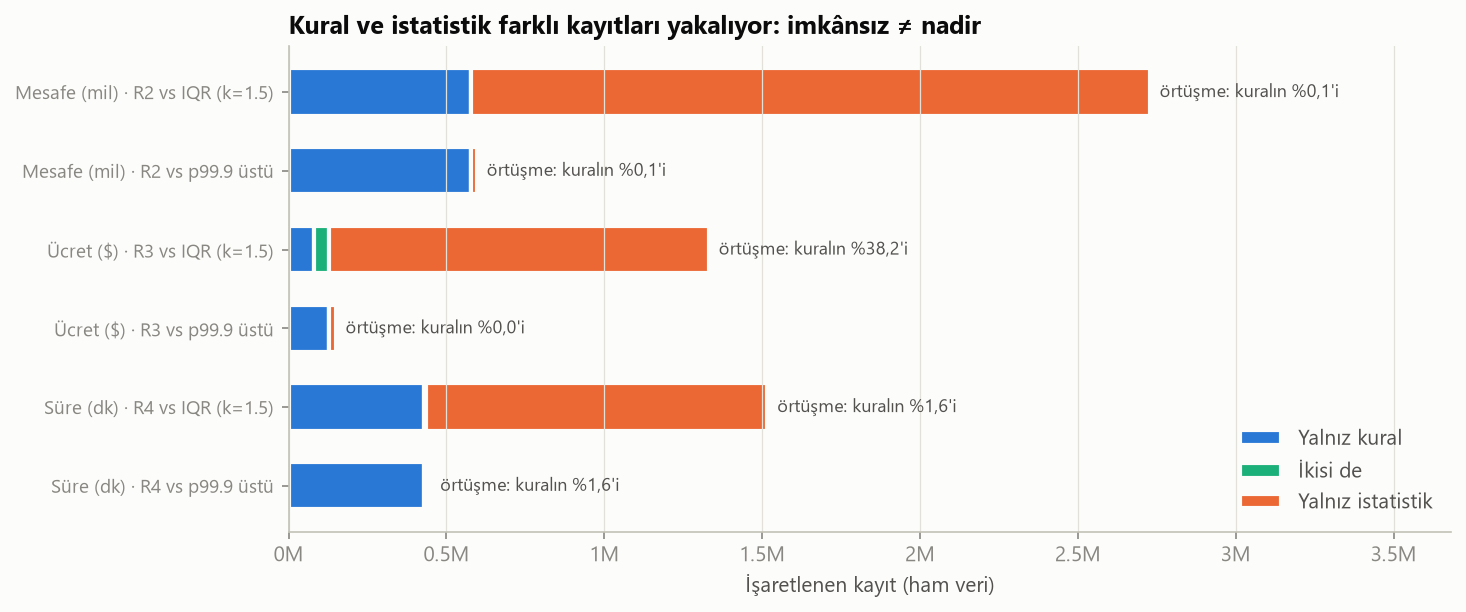

,metric,rule,stat_method,stat_threshold,rule_flagged,stat_flagged,both,rule_only,stat_only
0,trip_distance,R2,IQR (k=1.5),"[-3.10, 7.86]",577511,2150631,767,576744,2149864
1,trip_distance,R2,p99.9 üstü,> 29.91,577511,19354,767,576744,18587
2,fare_amount,R3,IQR (k=1.5),"[-15.20, 52.00]",129194,1251013,49312,79882,1201701
3,fare_amount,R3,p99.9 üstü,> 143.00,129194,19665,0,129194,19665
4,trip_duration_min,R4,IQR (k=1.5),"[-12.43, 42.77]",436497,1086898,7147,429350,1079751
5,trip_duration_min,R4,p99.9 üstü,> 125.30,436497,19200,7145,429352,12055


In [6]:
display(Image(pc.plot_rule_vs_stat(read("anomaly_rule_vs_stat"), FIG)))
read("anomaly_rule_vs_stat")

**Neden neredeyse hiç örtüşmüyorlar?** Çünkü farklı soruları cevaplıyorlar:
- **Kural "imkânsız mı?"** diye sorar: negatif ücret, sıfır mesafe, 7 günlük yolculuk. Bunlar dağılımın içinde de olabilir (−5 $ ücret nadir değil, ama imkânsız).
- **İstatistik "nadir mi?"** diye sorar: 143 $'lık ücret nadir ama tamamen mümkün (uzun havalimanı yolculuğu). R3 ile p99,9 arasında **sıfır** örtüşme var.
- **IQR taksi verisine uymuyor:** IQR simetrik, normale yakın dağılım varsayar. Taksi ücreti sağa çarpık ve ağır kuyruklu; IQR üst sınırı 52 $ çıkıyor ve **1,25M kaydı (%6,6)** anomali sayıyor — bunların çoğu JFK sabit tarifesi (~70 $) gibi meşru yolculuklar. Alt sınırı ise negatif (−15 $), yani sıfır ücreti bile yakalamıyor.

**Sonuç:** Temizlik için kural (alan bilgisi), anomali keşfi için istatistik gerekir; biri diğerinin yerini tutmaz. Global istatistiğin zayıflığı da bir sonraki adımı motive eder: **bağlam**.

## 5. Bağlama duyarlı anomali (window) ve ücret–mesafe tutarlılığı

Bir ücretin "aşırı" olup olmadığı güzergâha bağlıdır: 70 $ JFK→Manhattan için normal, aynı mahalle içinde 1 km için değil. Temiz veride her **güzergâh (biniş bölgesi → iniş bölgesi)** için **window** ile ücretin ve sürenin çeyrekleri hesaplandı:

```python
route = Window.partitionBy("PULocationID", "DOLocationID")
F.percentile_approx("fare_amount", [0.25, 0.5, 0.75]).over(route)
```

Anomali: güzergâhın kendi IQR'ının 3 katı dışı (k=3, globaldekinden sıkı). Sabit tarifeli güzergâhlarda IQR ≈ 0 olacağından IQR en az medyanın %20'si kabul edildi; 30'dan az yolculuklu güzergâhlar değerlendirilmedi (bağlam yetersiz).

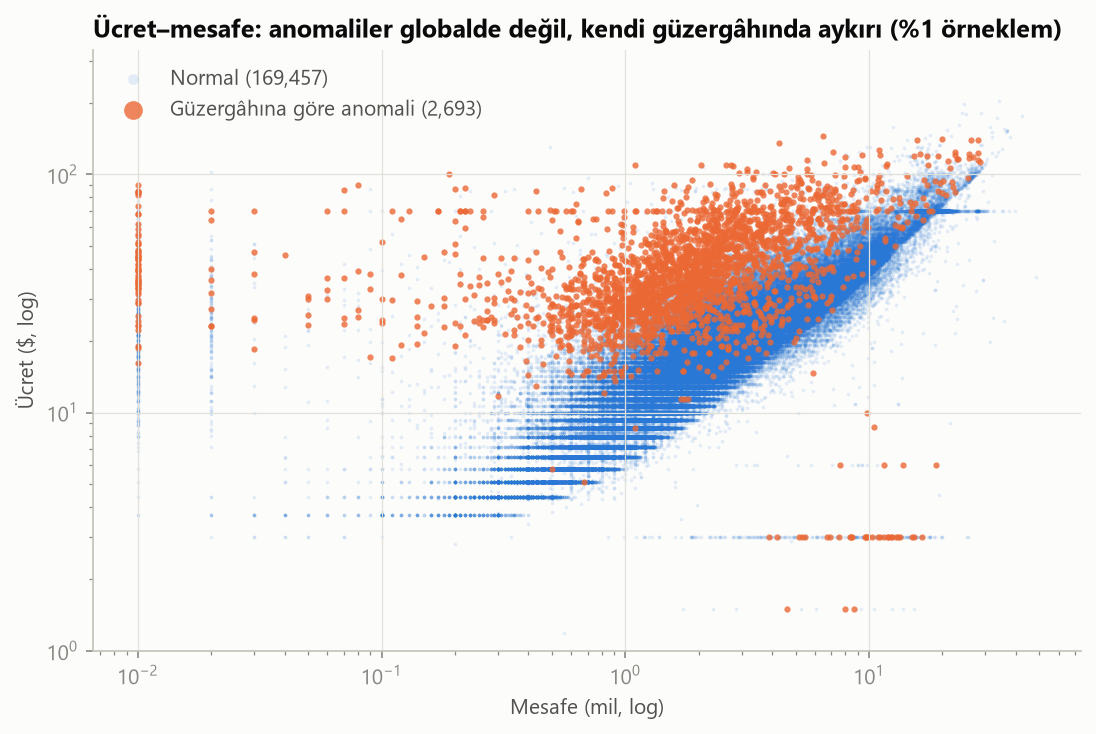

,metric,context_flagged,context_high,context_low,global_p999_flagged,both,context_only,global_only
0,fare_amount,272480,267308,5172,17672,4839,267641,12833
1,trip_duration_min,106984,106958,26,17403,3295,103689,14108


In [7]:
display(Image(pc.plot_fare_vs_distance(clean_s, FIG)))
read("anomaly_context")

**Neden bağlam globalden fazlasını buluyor?** Global p99,9 yalnızca 17.672 yüksek ücret işaretliyor; güzergâh bağlamı **272.480** (%1,6) — ve ikisinin örtüşmesi sadece 4.839. Grafikte turuncu noktalar global olarak sıradan ücretlerde (10–100 $) ama **mesafelerine göre** fazla yüksek: kısa mesafede gövdenin çok üstündeler. Global eşik bunları göremez, çünkü 60 $ tek başına nadir bir ücret değildir.

Grafiğin sağ altındaki **3 $ çizgisi** ters yönlü anomaliler: 10 mil yolculuğa açılış ücreti kadar ücret. En uç örnekler:

In [8]:
read("anomaly_examples")[["kind", "VendorID", "PULocationID", "DOLocationID", "trip_distance",
                           "trip_duration_min", "fare_amount", "fare_amount_route_median", "route_trips", "excess"]]

,kind,VendorID,PULocationID,DOLocationID,trip_distance,trip_duration_min,fare_amount,fare_amount_route_median,route_trips,excess
0,ctx_fare,2,225,45,5.29,36.93,"1,061.72",31.08,123,"1,030.64"
1,ctx_fare,2,216,216,1.19,7.75,950.00,9.37,851,940.63
2,ctx_fare,2,226,226,0.15,1.12,650.00,8.34,1485,641.66
3,ctx_fare,2,68,68,0.01,1.12,623.70,6.50,18732,617.20
4,ctx_fare,2,138,138,0.23,4.20,615.00,12.10,1892,602.90
5,ctx_duration,2,98,98,59.12,178.28,100.00,6.07,33,175.43
6,ctx_duration,1,186,186,16.70,179.38,135.30,7.20,4922,173.73
7,ctx_duration,1,186,186,15.70,177.75,130.40,7.20,4922,172.10
8,ctx_duration,2,132,132,4.01,179.97,19.10,18.40,11176,171.60
9,ctx_duration,2,132,132,15.02,179.95,55.50,18.40,11176,171.58


Örn. aynı bölge içinde (226→226) 0,15 mil için **650 $** — güzergâh medyanı 8,34 $. Aynı bölgede 1,12 dakika süren yolculuk için 623,70 $. Bunlar büyük olasılıkla elle yanlış girilmiş ücretler (fazladan basamak) ya da kayıt hataları.

**Ücret–mesafe tutarlılık kontrolleri:**

In [9]:
read("anomaly_consistency")

,check,rows,flex_fare_rows,also_context_flagged
0,kısa mesafe (<1 mil) + yüksek ücret (>100 $),492,293,297
1,yer tutucu ücret (0 < ücret < 3 $ açılış ücreti),2600,2052,291


- **Açılış ücretinin (3 $) altında ücret:** 2.600 kayıt, **%79'u Flex Fare**. Flex Fare'de `fare_amount` taksimetre ücreti değil; ön fiyat başka kalemlere dağıtılıyor olabilir. Yani bu "anomali" kısmen yine Flex Fare'nin farklı kayıt düzeninden kaynaklanıyor.
- **Kısa mesafe + > 100 $:** 492 kayıt; %60'ı Flex Fare (mesafe kaydedilmemiş olabilir), %60'ını bağlamsal yöntem de yakalıyor.

## 6. Anomaliler nerede yoğunlaşıyor? (join + aggregation)

Kayıtlar taxi zone lookup tablosuyla **join** edilerek biniş ilçesi eklendi; kural ve anomali oranları sağlayıcı, ilçe ve saat bazında hesaplandı.

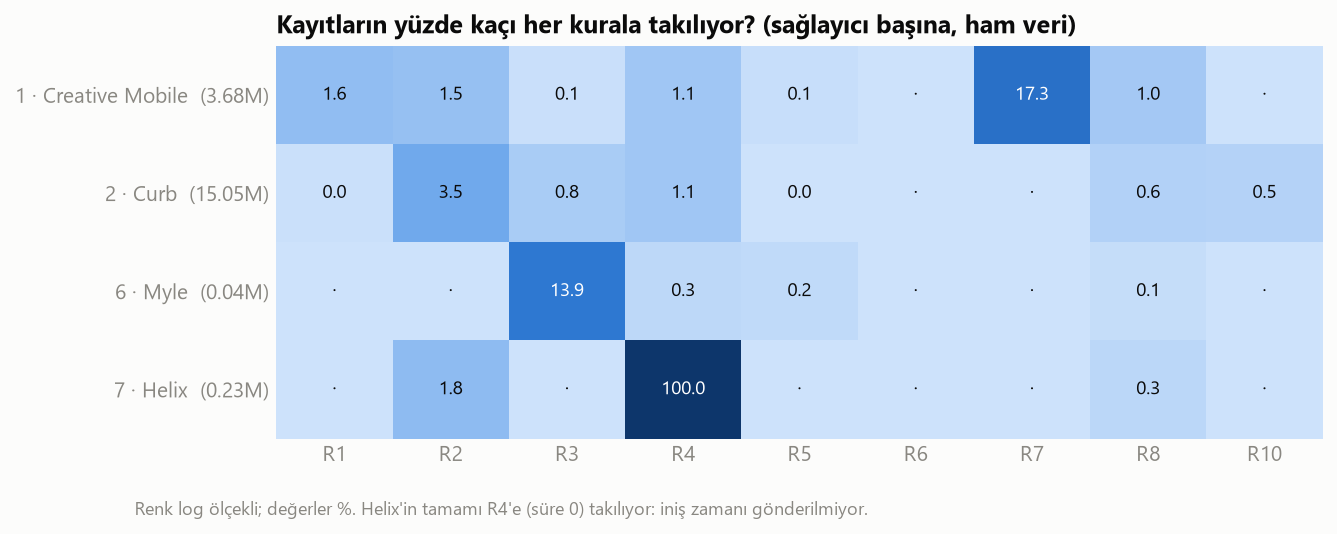

,dimension,value,rows,R1,R2,R3,R4,R5,R6,R7,R8,R10
4,pu_borough,Queens,1686998,0.18,3.30,1.72,4.33,0.05,0.00,5.67,2.67,0.36
5,pu_borough,EWR,2393,0.67,76.64,1.21,94.40,0.75,0.00,0.00,2.84,0.00
6,pu_borough,Unknown,21955,2.81,7.32,1.28,5.59,0.14,0.00,0.39,100.00,0.24
7,pu_borough,Brooklyn,764355,0.04,4.75,0.30,1.27,0.08,0.00,30.41,0.16,0.02
8,pu_borough,Staten Island,2031,0.05,8.52,4.87,7.93,0.30,0.00,6.70,0.44,0.00
9,pu_borough,NaN,7764,0.57,52.74,3.13,64.98,1.65,0.00,2.61,100.00,0.14
10,pu_borough,Manhattan,16330620,0.37,2.89,0.59,2.10,0.02,0.00,1.29,0.27,0.43
11,pu_borough,Bronx,183166,0.02,3.46,0.37,1.39,0.19,0.00,53.57,0.19,0.01


In [10]:
display(Image(pc.plot_rule_rates_heatmap(read("anomaly_rule_rates"), FIG)))
read("anomaly_rule_rates").query("dimension == 'pu_borough'")

**Hataların kaynağı tek tek kayıtlar değil, veri sağlayıcıları:**
- **Helix (Vendor 7): kayıtlarının %100'ü R4'e takılıyor.** Her kayıtta iniş zamanı = biniş zamanı (süre 0), ama mesafe ve ücret normal → bu sağlayıcı iniş zamanını **hiç göndermiyor**. Sonuç: temiz veride Helix hiç yok (234.756 yolculuk, ham verinin %1,2'si).
- **Creative Mobile (Vendor 1): kayıtlarının %17,3'ü R7** (`RatecodeID = 99`); R7'nin %99,9'u bu sağlayıcıdan. Bronx'ta kayıtların %54'ü, Brooklyn'de %30'u R7 → bu sağlayıcı dış ilçelerde yaygın ve tarife kodunu göndermiyor. R7 ile silinmeleri dış ilçelerin temiz verideki payını düşürür (**Öğrenci 3'ün ilçe analizine etki**).
- **Myle (Vendor 6): %13,9'u R3** (ücret ≤ 0) ve temiz veride bile bağlamsal anomali oranı %14 (diğerlerinde %1–2) → bu sağlayıcının ücret kayıtları güvenilmez.
- **Curb (Vendor 2):** negatif ücretlerin (iadeler) tamamı bu sağlayıcıdan; %89'unun aynı zaman/bölge/tutarda pozitif bir eşi var → orijinal yolculuğun ters kaydı.
- **EWR (Newark havalimanı) çıkışlı** kayıtların %94'ü R4'e takılıyor (çok az kayıt; şehir dışı yolculuk kayıt düzeni farklı).

In [11]:
p = read("anomaly_patterns")
p[(p["source"].str.startswith("clean")) & (p["dimension"] == "pickup_hour")].sort_values("rate_pct", ascending=False).head(6)

,source,dimension,value,rows,anomalies,rate_pct
40,clean: bağlamsal anomali,pickup_hour,8,691150,22311,3.23
54,clean: bağlamsal anomali,pickup_hour,4,136877,4179,3.05
58,clean: bağlamsal anomali,pickup_hour,21,1086444,31859,2.93
36,clean: bağlamsal anomali,pickup_hour,7,521671,15105,2.90
43,clean: bağlamsal anomali,pickup_hour,0,543404,14816,2.73
51,clean: bağlamsal anomali,pickup_hour,1,361840,9693,2.68


Temiz veride bağlamsal anomali oranı sabah 4 ve 7–8'de, gece 21–00'da daha yüksek (%2,7–3,2, ortalama %1,95). Bu saatlerde güzergâh başına yolculuk az ve trafik koşulları değişken → aynı güzergâhta süre/ücret dağılımı daha geniş.

## 7. Sonuç (Öğrenci 2 katkısı)

1. **Eksik veri sistematik:** null'ların tamamı Flex Fare kayıtlarında. Naif `dropna()` verinin %25'ini yok ederdi; kural bazlı temizlik %9,4 sildi ve her silmenin gerekçesi var.
2. **Hataların büyük kısmı kaynakta:** Helix iniş zamanı, Creative Mobile tarife kodu göndermiyor; Myle'ın ücretleri güvenilmez; iadeler Curb'ün ters kayıtları. Kayıt bazlı temizlik bu kaynak hatalarını "tek tek hatalı kayıt" gibi siler — **sağlayıcı bazında bütün bir alt küme kaybolabilir** (Helix'in tamamı).
3. **Temizlik tipik değerleri değil kuyrukları değiştirir:** medyanlar aynı kaldı, ortalamalar %43'e varan oranda düştü.
4. **Kural ≠ istatistik:** kural imkânsızı, istatistik nadiri bulur; örtüşmeleri neredeyse sıfır. Global IQR ağır kuyruklu taksi verisine uymaz.
5. **Bağlam önemlidir:** güzergâh bazlı (window) analiz, global eşiğin 15 katı ücret anomalisi buluyor ve bunlar global eşikle neredeyse hiç örtüşmüyor.

**Hatalı kayıtların olası kaynakları:** taksimetre/sağlayıcı yazılımı (eksik alan, süre 0), iade ve ters kayıtlar (negatif ücret), iptal edilen yolculuklar (sıfır mesafe + saniyeler süren kayıt), elle giriş hataları (aynı bölgede 650 $), sistem saati hataları (2001 tarihli kayıtlar), ön fiyatlı yolculukların farklı kayıt düzeni (Flex Fare).

**Sonraki öğrencilere etkisi:** Öğrenci 3/4/5 `data/clean` kullanmalı; Flex Fare kayıtları (`is_flex_fare`) 5 kolonda null'dur; Helix temiz veride yoktur ve dış ilçelerin payı R7 nedeniyle azalmıştır; `fare_amount` hâlâ güzergâh bazlı uç değerler içerir (silinmedi, analiz edildi).

**Sınırlamalar:** R7 (638K) ve Flex Fare + sıfır mesafe (407K) kayıtlarının profili gerçek yolculuk olduklarını düşündürüyor; proje kararıyla silindiler (bkz. `cleaning_rules.md` §5). Bağlamsal anomali eşikleri (k=3, %20 IQR alt sınırı, 30 yolculuk) seçimdir; farklı eşikler farklı sayılar verir. Zaman damgaları saat dilimsiz; yaz saati geçişini kapsayan birkaç yolculukta süre ±60 dk sapabilir.